. Task 1: E-Commerce Dataset Cleaning

Task Objective

Clean an e-commerce dataset containing transactional, product, customer, or order-related
data. This task is intended to build strong habits in preparing data before analysis.

Typical Dataset Fields
The dataset may contain columns such as:

Order ID,
Customer ID,
Product Name,
Category,
Quantity,
Unit Price,
Total Amount,
Order Date,
Payment Mode,
Delivery Status,
City or Region


In [78]:
import pandas as pd

In [79]:
df = pd.read_csv(r"C:\Users\chetana kusekar\Downloads\Ecommerce_Dirty_Dataset_200Rows.csv")

In [80]:
print(df.shape)

(202, 11)


In [81]:
print(df.head())

  Order ID Customer ID    Product Name     Category  Quantity  Unit Price  \
0  ORD0001    CUST0001         Printer  Electronics       2.0        50.0   
1  ORD0002    CUST0002          Router  electronics       2.0         NaN   
2  ORD0003    CUST0003  Wireless Mouse  Electronics       1.0       150.0   
3  ORD0004    CUST0004      Coffee Mug         home       4.0         0.0   
4  ORD0005    CUST0005         Monitor  Electronics      -2.0       700.0   

   Total Amount  Order Date Payment Mode Delivery Status City or Region  
0         100.0  2024-05-20         Card         Pending       Vadodara  
1           NaN  2024-10-06          UPI             NaN           Pune  
2         150.0  2024-04-21         Card        Returned      Ahmedabad  
3           0.0  2024-11-28          NaN      In-Transit         Rajkot  
4       -1400.0  2024-01-04         Card      In-Transit         Mumbai  


In [82]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202 entries, 0 to 201
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order ID         202 non-null    object 
 1   Customer ID      202 non-null    object 
 2   Product Name     202 non-null    object 
 3   Category         202 non-null    object 
 4   Quantity         177 non-null    float64
 5   Unit Price       185 non-null    float64
 6   Total Amount     161 non-null    float64
 7   Order Date       202 non-null    object 
 8   Payment Mode     161 non-null    object 
 9   Delivery Status  187 non-null    object 
 10  City or Region   202 non-null    object 
dtypes: float64(3), object(8)
memory usage: 17.5+ KB
None


In [83]:
# Missing Value

print(df.isnull().sum())


Order ID            0
Customer ID         0
Product Name        0
Category            0
Quantity           25
Unit Price         17
Total Amount       41
Order Date          0
Payment Mode       41
Delivery Status    15
City or Region      0
dtype: int64


In [84]:
missing_percentage = ( df.isnull().sum() / len(df)) * 100
print(missing_percentage)

Order ID            0.000000
Customer ID         0.000000
Product Name        0.000000
Category            0.000000
Quantity           12.376238
Unit Price          8.415842
Total Amount       20.297030
Order Date          0.000000
Payment Mode       20.297030
Delivery Status     7.425743
City or Region      0.000000
dtype: float64


In [85]:
# check Outliers
import matplotlib.pyplot as plt
import seaborn as sns

# Outliers checks for Quantity , Unit price and Total amount 
# Convert to numeric
df["Quantity"] = pd.to_numeric(df["Quantity"] , errors ="ignore" )
df["Unit Price"] = pd.to_numeric(df["Unit Price"] , errors = "ignore")
df["Total Amount"] = pd.to_numeric(df["Total Amount"] , errors = "ignore")


C:\Users\chetana kusekar\AppData\Local\Temp\ipykernel_4344\2757793165.py:7: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df["Quantity"] = pd.to_numeric(df["Quantity"] , errors ="ignore" )
C:\Users\chetana kusekar\AppData\Local\Temp\ipykernel_4344\2757793165.py:8: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df["Unit Price"] = pd.to_numeric(df["Unit Price"] , errors = "ignore")
C:\Users\chetana kusekar\AppData\Local\Temp\ipykernel_4344\2757793165.py:9: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df["Total Amount"] = pd.to_numeric(df["Total Amount"] , errors = "ignore")


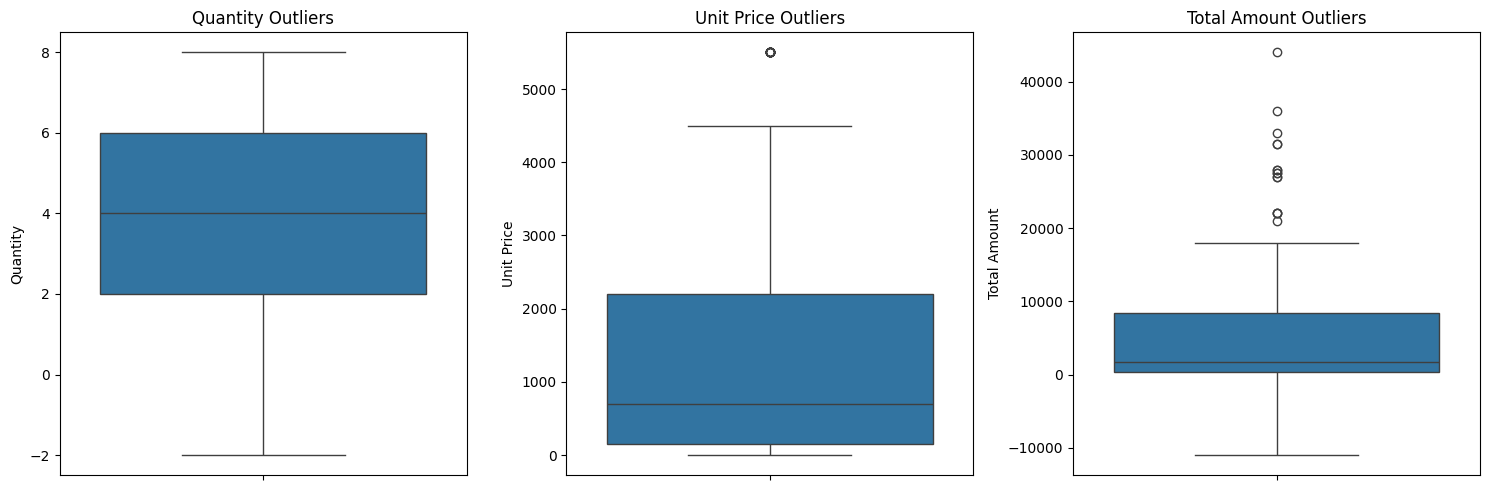

In [86]:
# Boxplot
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
sns.boxplot(y=df['Quantity'])
plt.title("Quantity Outliers")

plt.subplot(1,3,2)
sns.boxplot(y=df['Unit Price'])
plt.title("Unit Price Outliers")

plt.subplot(1,3,3)
sns.boxplot(y=df['Total Amount'])
plt.title("Total Amount Outliers")

plt.tight_layout()
plt.show()



1.Raw Dataset Inspection Summary

•	Dataset: Ecommerce_Dirty_Dataset_200Rows.csv

•	Total Rows: 202

•	Total Columns: 11

•	Checked data types, missing values, duplicates, and column structure


In [87]:
# Remove Missing values of numerical columns:
df["Quantity"].fillna(df["Quantity"].median() , inplace = True)

df["Unit Price"].fillna(df["Unit Price"].median() , inplace = True)

df["Total Amount"].fillna(df["Unit Price"].median() , inplace = True)

C:\Users\chetana kusekar\AppData\Local\Temp\ipykernel_4344\1694850958.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Quantity"].fillna(df["Quantity"].median() , inplace = True)
C:\Users\chetana kusekar\AppData\Local\Temp\ipykernel_4344\1694850958.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values a

In [88]:
# Remove missing valuues of categorical columns:-

df["Payment Mode"].fillna("Unknown" , inplace = True)

df["Delivery Status"].fillna("Unknown" , inplace = True)

C:\Users\chetana kusekar\AppData\Local\Temp\ipykernel_4344\1490155805.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Payment Mode"].fillna("Unknown" , inplace = True)
C:\Users\chetana kusekar\AppData\Local\Temp\ipykernel_4344\1490155805.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beha

In [89]:
print(df.isnull().sum())

Order ID           0
Customer ID        0
Product Name       0
Category           0
Quantity           0
Unit Price         0
Total Amount       0
Order Date         0
Payment Mode       0
Delivery Status    0
City or Region     0
dtype: int64


2. Missing Value Report

Column	                          Action Taken

Quantity	                       Filled with Median

Unit Price	                       Filled with Median

Category	                       Filled with "Unknown"

Payment Mode	                   Filled with "Unknown"

Delivery Status	                   Filled with "Unknown"

Reason: Median reduces the impact of outliers, while "Unknown" preserves incomplete records.



In [90]:
# Duplicate Analysis :-
print(df.duplicated().sum())


2


In [91]:
duplicate_orders = df[df["Order ID"].duplicated()]

print(duplicate_orders)

    Order ID Customer ID Product Name     Category  Quantity  Unit Price  \
200  ORD0050    CUST0050      Monitor  Electronics       4.0         0.0   
201  ORD0100    CUST0100     Keyboard  electronics       1.0       700.0   

     Total Amount  Order Date Payment Mode Delivery Status City or Region  
200         700.0  2024-06-03      Unknown        Returned      Ahmedabad  
201         700.0  2024-10-21  Net Banking      In-Transit         Rajkot  


In [92]:
df = df.drop_duplicates()

In [93]:
print(df.duplicated().sum())

0


3. Duplicate Analysis Note

•	Checked full duplicate rows using:
df.duplicated().sum()

•	Investigated duplicate Order IDs.

•	Removed only confirmed duplicate records.
df = df.drop_duplicates()


In [94]:
#  Data Validation :-
# 1. Quantity - must be greater than 1

df[df["Quantity"] <= 0]


,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City or Region
4,ORD0005,CUST0005,Monitor,Electronics,-2.0,700.0,-1400.0,2024-01-04,Card,In-Transit,Mumbai
15,ORD0016,CUST0016,Router,electronics,-2.0,2200.0,-4400.0,2024-10-25,Net Banking,In Transit,Rajkot
18,ORD0019,CUST0019,USB Cable,Electronics,-2.0,3500.0,-7000.0,2024-09-27,Cash,Returned,Ahmedabad
24,ORD0025,CUST0025,Office Chair,Furniture,-2.0,150.0,-300.0,2024/13/01,Net Banking,delivered,Vadodara
47,ORD0048,CUST0048,Keyboard,electronics,-2.0,150.0,-300.0,2024-02-07,Unknown,Pending,Gandhinagar
67,ORD0068,CUST0068,USB Cable,Electronics,-2.0,500.0,-1000.0,2024-05-10,UPI,In-Transit,Ahmedabad
73,ORD0074,CUST0074,Marker,Stationary,-2.0,5500.0,-11000.0,2024-12-01,Cash,Cancelled,Jaipur
75,ORD0076,CUST0076,Coffee Mug,home,-2.0,1200.0,-2400.0,2024-02-17,Card,pending,Rajkot
91,ORD0092,CUST0092,USB Cable,Electronics,-2.0,5500.0,-11000.0,2024-12-05,UPI,delivered,Pune
98,ORD0099,CUST0099,Notebook,Stationery,-2.0,5500.0,-11000.0,2024-02-28,Card,pending,Surat


In [95]:
# clean negative quantity
df = df[df ["Quantity"] > 0]

In [96]:
df [df["Quantity"] <=0]

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City or Region


In [97]:
# 2. Unit Price - must be greater than 0
df[df["Unit Price"] <= 0]

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City or Region
3,ORD0004,CUST0004,Coffee Mug,home,4.0,0.0,0.0,2024-11-28,Unknown,In-Transit,Rajkot
8,ORD0009,CUST0009,Keyboard,electronics,4.0,0.0,0.0,2024-02-05,UPI,Pending,Gandhinagar
26,ORD0027,CUST0027,Office Chair,Furniture,4.0,0.0,700.0,2024-12-19,Card,pending,Pune
49,ORD0050,CUST0050,Monitor,Electronics,4.0,0.0,700.0,2024-06-03,Unknown,Returned,Ahmedabad
51,ORD0052,CUST0052,Bluetooth Speaker,Electronic,2.0,0.0,0.0,2024-10-10,Card,pending,Gandhinagar
52,ORD0053,CUST0053,Keyboard,electronics,4.0,0.0,0.0,2024-06-24,Card,pending,Jaipur
79,ORD0080,CUST0080,Office Chair,Furniture,3.0,0.0,0.0,2024-09-22,Net Banking,Delivered,Rajkot
85,ORD0086,CUST0086,Office Chair,Furniture,7.0,0.0,0.0,2024-03-19,Card,delivered,Pune
90,ORD0091,CUST0091,Water Bottle,Home,7.0,0.0,0.0,2024-03-25,Net Banking,DELIVERED,Ahmedabad
104,ORD0105,CUST0105,USB Cable,Electronics,3.0,0.0,0.0,2024-09-24,Cash,Unknown,Jaipur


In [98]:
#  Clean 
df = df[df["Unit Price"] > 0 ]

In [99]:
df[df["Unit Price"] <=0]

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City or Region


In [ ]:
# 3. Date Format check - invalid dates removed

df["Order Date"] = pd.to_datetime(df["Order Date"] , errors = "ignore")

C:\Users\chetana kusekar\AppData\Local\Temp\ipykernel_4344\3707535415.py:3: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  df["Order Date"] = pd.to_datetime(df["Order Date"] , errors = "ignore")


In [101]:
df["Order Date"]

0      2024-05-20
1      2024-10-06
2      2024-04-21
5      2024-06-21
6      2024-11-05
          ...    
194    2024-01-23
195    2024-09-02
196    2024-02-11
197    2024-11-15
199    2024-11-29
Name: Order Date, Length: 166, dtype: object

In [102]:
# 4. Category Standardization :-
df["Category"]

0      Electronics
1      electronics
2      Electronics
5       Home Decor
6       Electronic
          ...     
194           home
195    Electronics
196    Electronics
197     Electronic
199     Electronic
Name: Category, Length: 166, dtype: object

In [103]:
df["Category"] = (df["Category"].replace({"Electronic":"Electronics","electronics": "Electronics","home":"Home","Stationary":
            "Stationery"}))

#Category names standardized

Electronic → Electronics

electronics → Electronics

home → Home

Stationary → Stationery


In [104]:
# 5.Delivery Status Standardization
df["Delivery Status"]

0         Pending
1         Unknown
2        Returned
5       delivered
6       Delivered
          ...    
194       pending
195    In-Transit
196       Unknown
197      Returned
199       Pending
Name: Delivery Status, Length: 166, dtype: object

In [105]:
df["Delivery Status"] = (df["Delivery Status"].replace({"delivererd":"Delivered" ,"DELIVERED" : "Delivered" , "pending" : "Pending", "In-Transit" : "In Transit"}))

In [106]:
df["Delivery Status"]

0         Pending
1         Unknown
2        Returned
5       delivered
6       Delivered
          ...    
194       Pending
195    In Transit
196       Unknown
197      Returned
199       Pending
Name: Delivery Status, Length: 166, dtype: object

#Delivery Status standardized

delivered → Delivered

DELIVERED → Delivered

pending → Pending

In-Transit → In Transit


In [107]:
# 6.Total amount Verification
# Total Amount = Quantity * Unit Price

df["Total Amount"] = df["Quantity"] * df["Unit Price"] 

In [108]:
df.columns

Index(['Order ID', 'Customer ID', 'Product Name', 'Category', 'Quantity',
       'Unit Price', 'Total Amount', 'Order Date', 'Payment Mode',
       'Delivery Status', 'City or Region'],
      dtype='object')

In [110]:
# Save Cleaned Dataset
df.to_csv("ecommerce_cleaned.csv" , index = False)

print("Cleaned dataset saved successfully !")

Cleaned dataset saved successfully !


In [112]:
# Load cleaned dataset
clean_df = pd.read_csv("ecommerce_cleaned.csv")

print(clean_df.head())


  Order ID Customer ID       Product Name     Category  Quantity  Unit Price  \
0  ORD0001    CUST0001            Printer  Electronics       2.0        50.0   
1  ORD0002    CUST0002             Router  Electronics       2.0       700.0   
2  ORD0003    CUST0003     Wireless Mouse  Electronics       1.0       150.0   
3  ORD0006    CUST0006          Desk Lamp   Home Decor       3.0       500.0   
4  ORD0007    CUST0007  Bluetooth Speaker  Electronics       6.0      1200.0   

   Total Amount  Order Date Payment Mode Delivery Status City or Region  
0         100.0  2024-05-20         Card         Pending       Vadodara  
1        1400.0  2024-10-06          UPI         Unknown           Pune  
2         150.0  2024-04-21         Card        Returned      Ahmedabad  
3        1500.0  2024-06-21          UPI       delivered           Pune  
4        7200.0  2024-11-05         Cash       Delivered         Jaipur  


In [115]:
# Final validation

print("Final Dataset Shape:", clean_df.shape)
print("Missing Values:")
print(clean_df.isnull().sum())

print("Duplicate Records:")
print(clean_df.duplicated().sum())

Final Dataset Shape: (166, 11)
Missing Values:
Order ID           0
Customer ID        0
Product Name       0
Category           0
Quantity           0
Unit Price         0
Total Amount       0
Order Date         0
Payment Mode       0
Delivery Status    0
City or Region     0
dtype: int64
Duplicate Records:
0


In [116]:
# Save Cleaned dataset
df.to_csv(r"C:\Users\chetana kusekar\Downloads\ecommerce_cleaned.csv" , index = False)

print("File Saved Successfully")

File Saved Successfully


# Explanation of Cleaning Decisions
Missing numerical values were replaced using the median, while missing categorical values were filled with "Unknown" to retain useful records. Duplicate rows were identified and removed after verification. Invalid quantities, prices, and dates were removed to maintain data quality. Category names and delivery statuses were standardized to ensure consistency. Finally, Total Amount was recalculated to ensure accurate transaction values.

# Conclusion
The dataset was successfully cleaned by handling missing values, removing duplicates, validating data quality rules, and standardizing categorical fields. The final dataset is ready for analysis, visualization, and reporting. 

